# 03 — Cartes et courbes d'évolution

À lancer après `scripts/ingest.py`, `scripts/detecter_s2.py` et `scripts/affiner_s2.py`.

1. Carte générale : les 7 baies, leurs sites CEVA et les stations de débit et de nitrates utilisées.
2. Où les ulves s'échouent : fréquence de détection par pixel (scènes de basse mer, avril-octobre, 2016-2025).
3. Comparaison des années, baie par baie.
4. Courbes : saisonnalité mensuelle et série annuelle 2016-2025 (CEVA puis satellite).

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection

RACINE = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RACINE / "src"))
from algathon.series_annuelles import charger_config
from algathon.ingestion import ceva, hubeau

P = RACINE / "data" / "processed"
config = charger_config()
baies = config["baies"]
COULEURS = dict(zip(baies, ["#264653", "#2a9d8f", "#8ab17d", "#e9c46a", "#f4a261", "#e76f51", "#9b5de5"]))

def polygones(geom):
    """Anneaux extérieurs d'un Polygon ou MultiPolygon GeoJSON."""
    parts = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
    return [np.array(p[0]) for p in parts]

## 1. Carte générale

Text(0, 0.5, 'latitude')

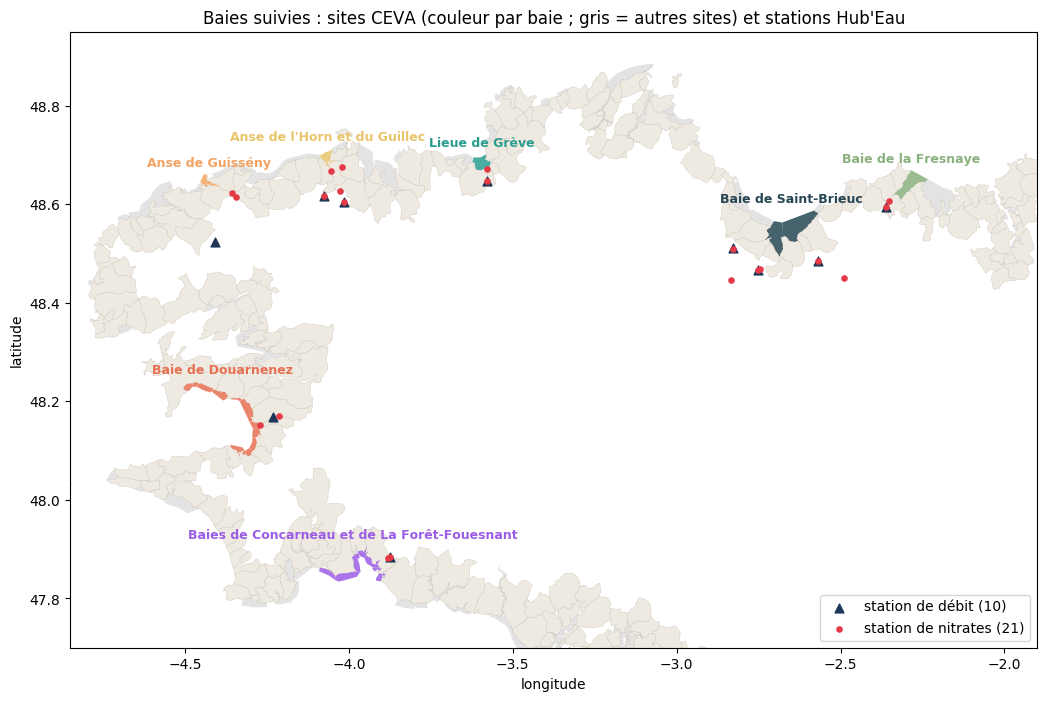

In [2]:
communes = ceva.telecharger_couche(ceva.COUCHE_ENQUETES)
sites = ceva.telecharger_couche(ceva.COUCHE_SITES)
codes_q = [r["debit"] for b in baies.values() for r in b["rivieres"]]
codes_n = [c for b in baies.values() for r in b["rivieres"] for c in r["nitrates"]]
st_q = hubeau.coordonnees_stations(codes_q, "debit")
st_n = hubeau.coordonnees_stations(codes_n, "nitrates")

fig, ax = plt.subplots(figsize=(13, 8))
terre = [Polygon(p) for f in communes["features"] for p in polygones(f["geometry"])]
ax.add_collection(PatchCollection(terre, facecolor="#eeeae2", edgecolor="#cfc8bb", linewidth=0.3))
id_vers_baie = {i: k for k, b in baies.items() for i in b["sites_ceva"]}
for f in sites["features"]:
    b = id_vers_baie.get(int(f["properties"]["ID"]))
    for p in polygones(f["geometry"]):
        ax.add_patch(Polygon(p, facecolor=COULEURS[b] if b else "#bbbbbb",
                             alpha=0.85 if b else 0.4, edgecolor="none"))
for k, b in baies.items():
    e = b["emprise"]
    ax.annotate(b["nom"].split("(")[0].strip(), ((e[0] + e[2]) / 2, e[3]), xytext=(0, 6),
                textcoords="offset points", ha="center", fontsize=9, color=COULEURS[k], weight="bold")
ax.scatter(st_q["lon"].astype(float).values, st_q["lat"].astype(float).values, marker="^", s=40,
           color="#1d3557", label="station de débit (%d)" % len(st_q), zorder=5)
ax.scatter(st_n["lon"].astype(float).values, st_n["lat"].astype(float).values, marker="o", s=14,
           color="#e63946", label="station de nitrates (%d)" % len(st_n), zorder=5)
ax.set_xlim(-4.85, -1.9); ax.set_ylim(47.7, 48.95)
ax.set_aspect(1 / np.cos(np.radians(48.3)))
ax.legend(loc="lower right")
ax.set_title("Baies suivies : sites CEVA (couleur par baie ; gris = autres sites) et stations Hub'Eau")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")

## 2. Où s'échouent les ulves ?

Part des scènes de basse mer (avril-octobre, 2016-2025) où chaque pixel a un NDVI > 0,2.
En gris : la zone analysée ; en bleu : les pixels exclus (végétation permanente et liseré côtier).

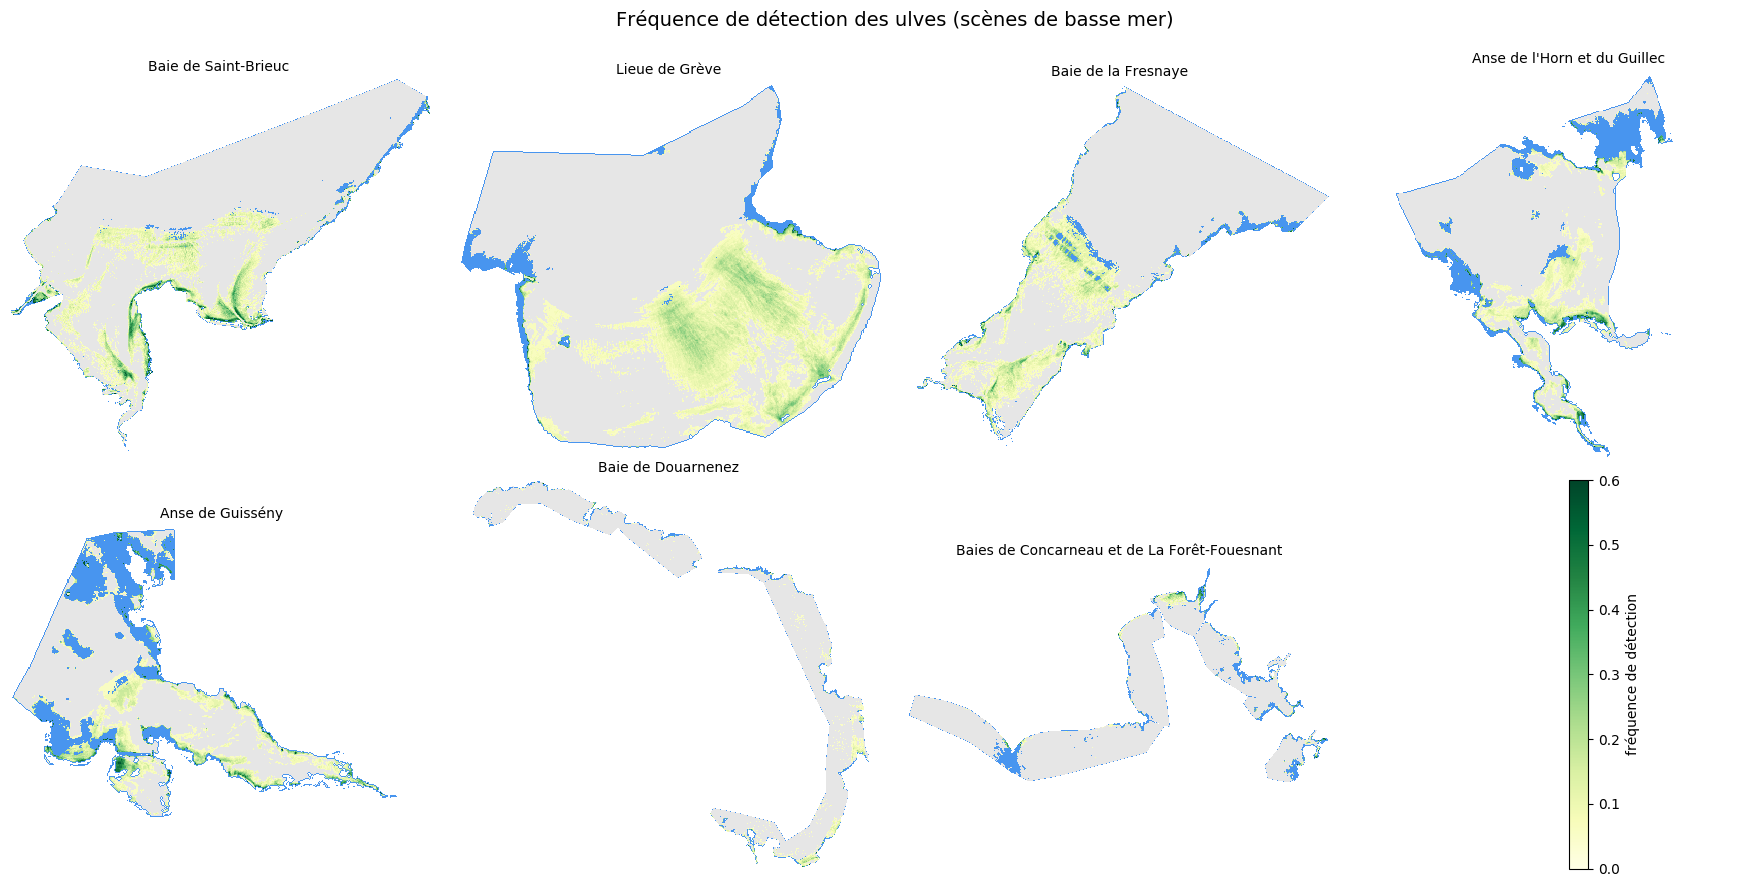

In [3]:
from matplotlib.colors import ListedColormap
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, k in zip(axes.flat, baies):
    z = np.load(P / "s2_cartes" / (k + ".npz"))
    ax.imshow(np.where(z["zone"], 1, np.nan), cmap=ListedColormap(["#e6e6e6"]))
    ax.imshow(np.where(z["permanent"] | z["lisere"], 1, np.nan), cmap=ListedColormap(["#4895ef"]))
    f = np.where(z["zone"] & ~(z["permanent"] | z["lisere"]), z["frequence"], np.nan)
    im = ax.imshow(np.where(f >= 0.05, f, np.nan), cmap="YlGn", vmin=0, vmax=0.6)
    ax.set_title(baies[k]["nom"].split("(")[0], fontsize=10)
    ax.axis("off")
axes.flat[-1].axis("off")
fig.colorbar(im, ax=axes.flat[-1], fraction=0.5, label="fréquence de détection")
fig.suptitle("Fréquence de détection des ulves (scènes de basse mer)", fontsize=14)
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 3. Une carte par année

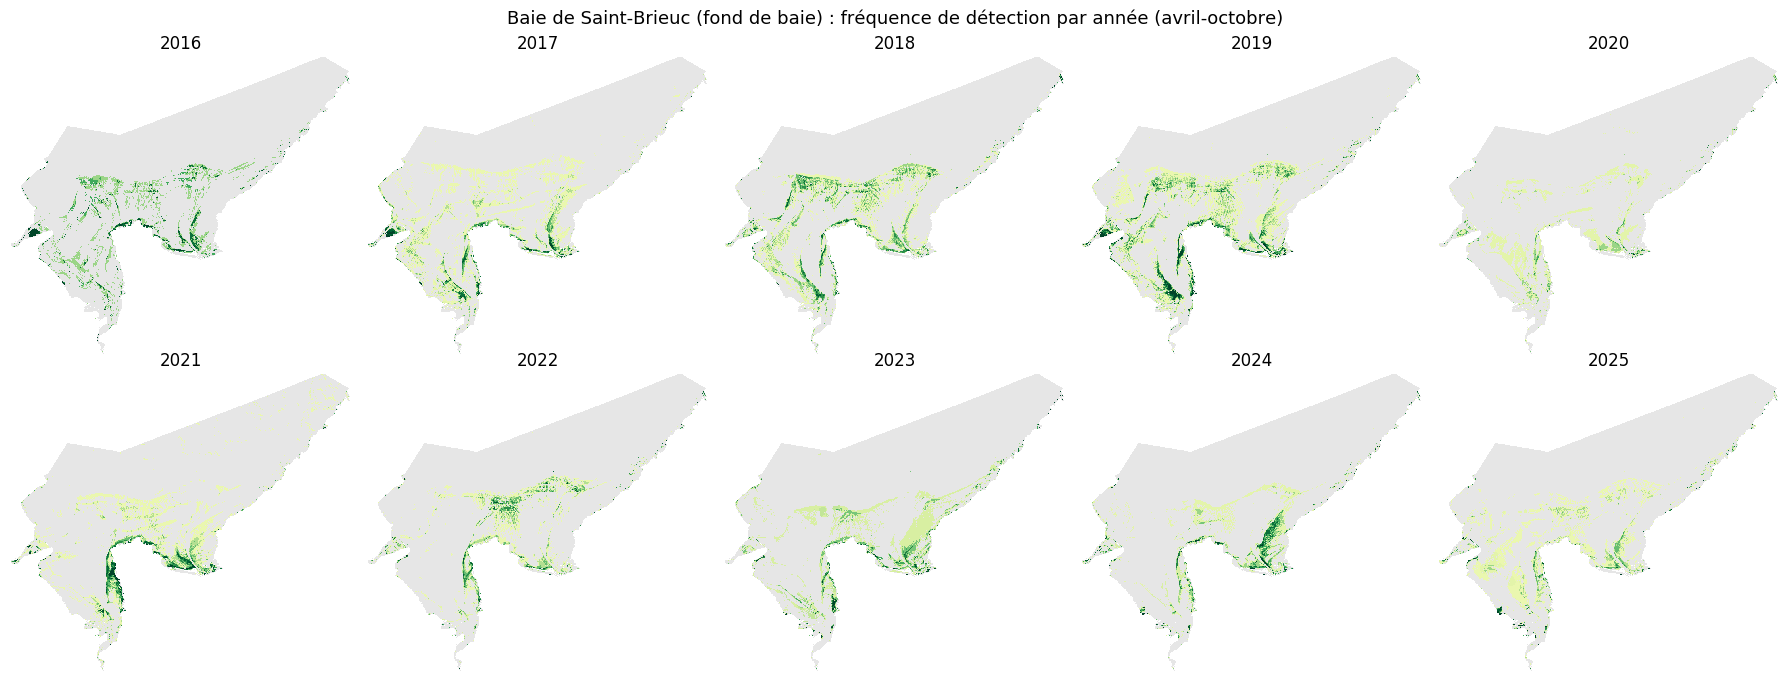

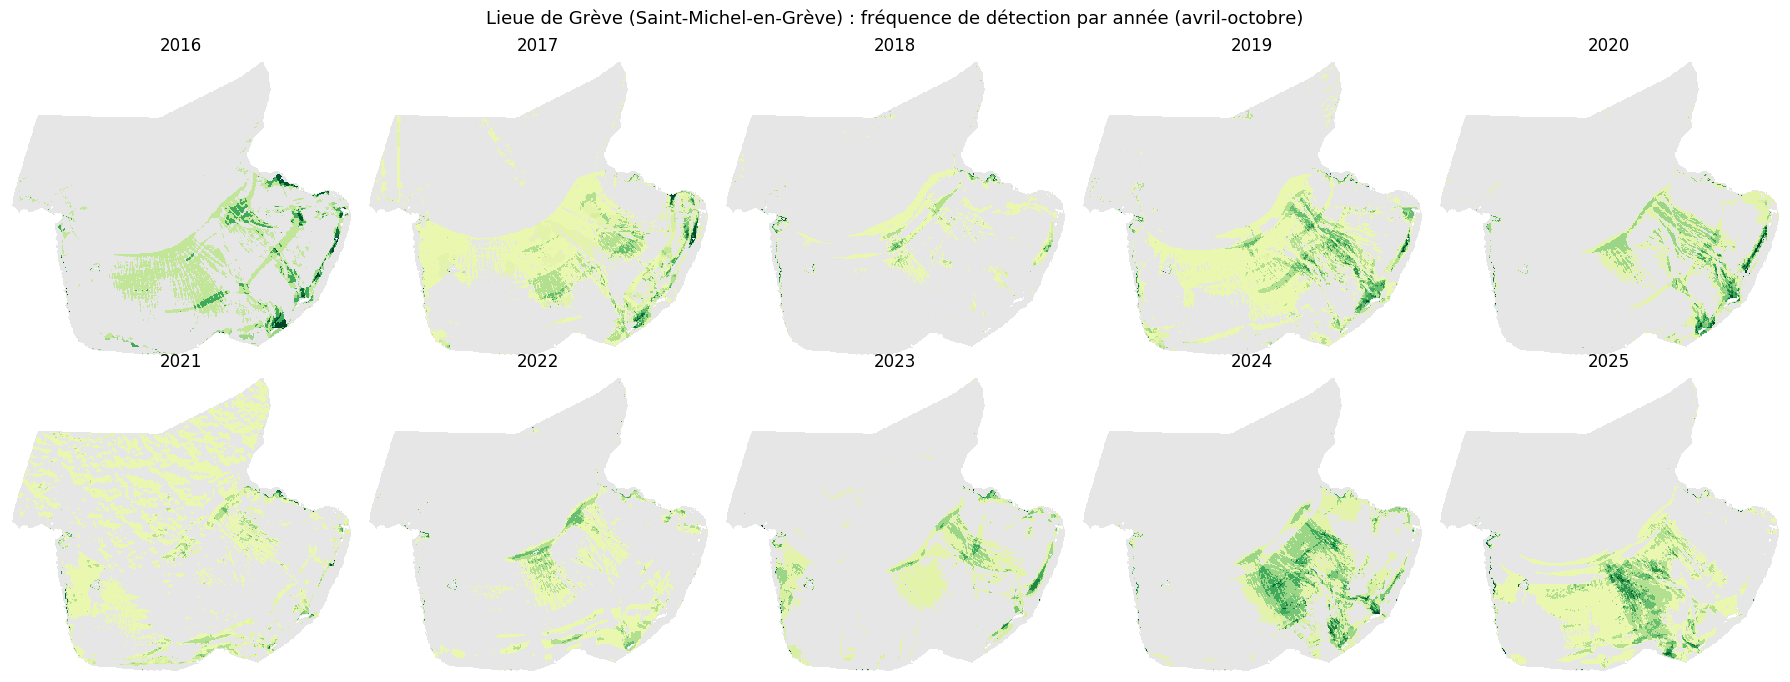

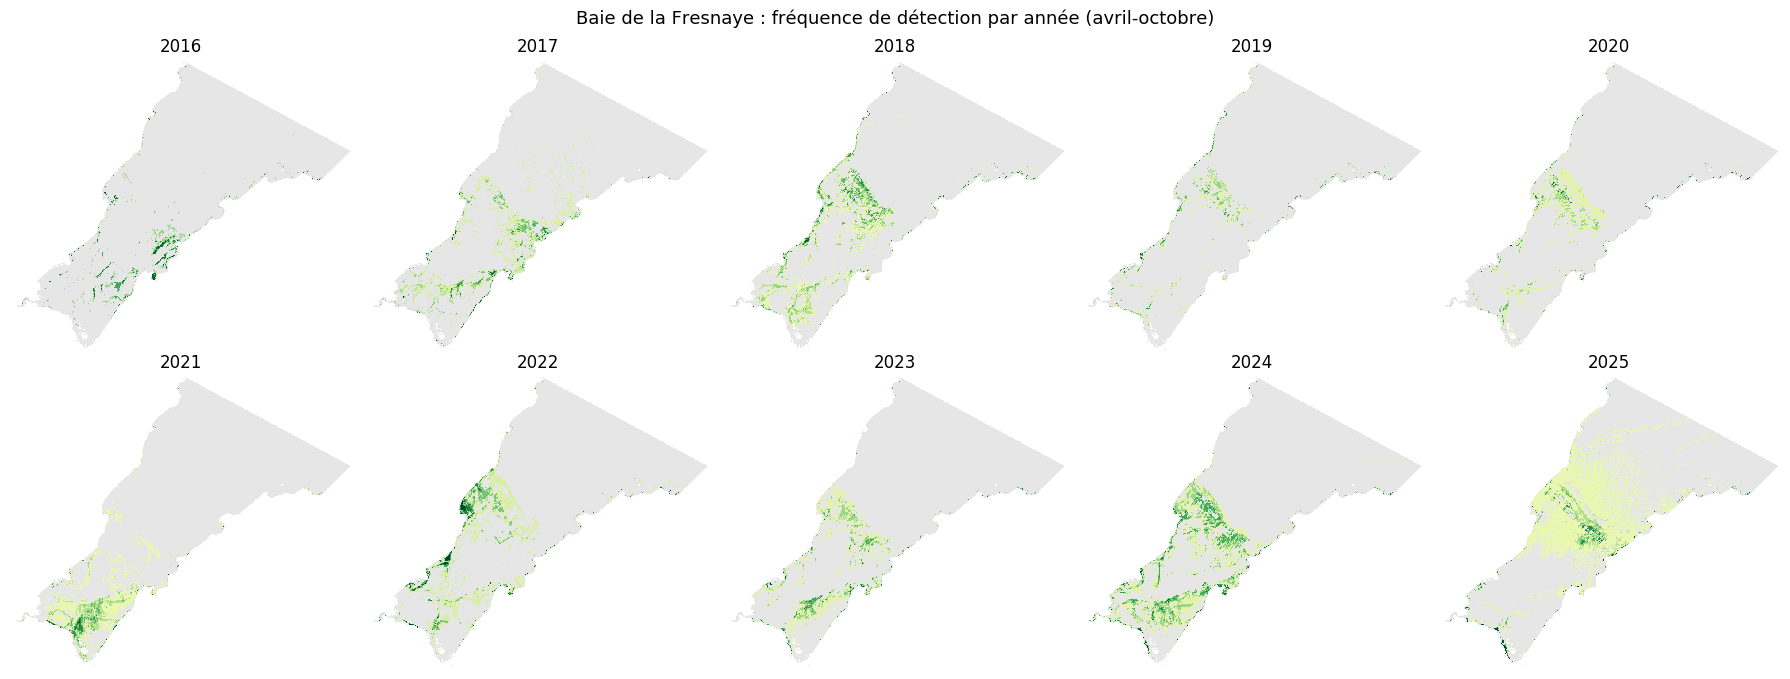

In [4]:
for k in ["saint_brieuc", "lieue_de_greve", "fresnaye"]:
    z = np.load(P / "s2_cartes" / (k + ".npz"))
    excl = z["permanent"] | z["lisere"]
    annees = list(z["annees"])
    fig, axes = plt.subplots(2, 5, figsize=(18, 7))
    for ax in axes.flat:
        ax.axis("off")
    for ax, a, fa in zip(axes.flat, annees, z["freq_annees"]):
        ax.imshow(np.where(z["zone"], 1, np.nan), cmap=ListedColormap(["#e6e6e6"]))
        f = np.where(z["zone"] & ~excl, fa, np.nan)
        ax.imshow(np.where(f >= 0.05, f, np.nan), cmap="YlGn", vmin=0, vmax=0.8)
        ax.set_title(str(a))
    fig.suptitle("%s : fréquence de détection par année (avril-octobre)" % baies[k]["nom"], fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.95])

## 4. Courbes d'évolution

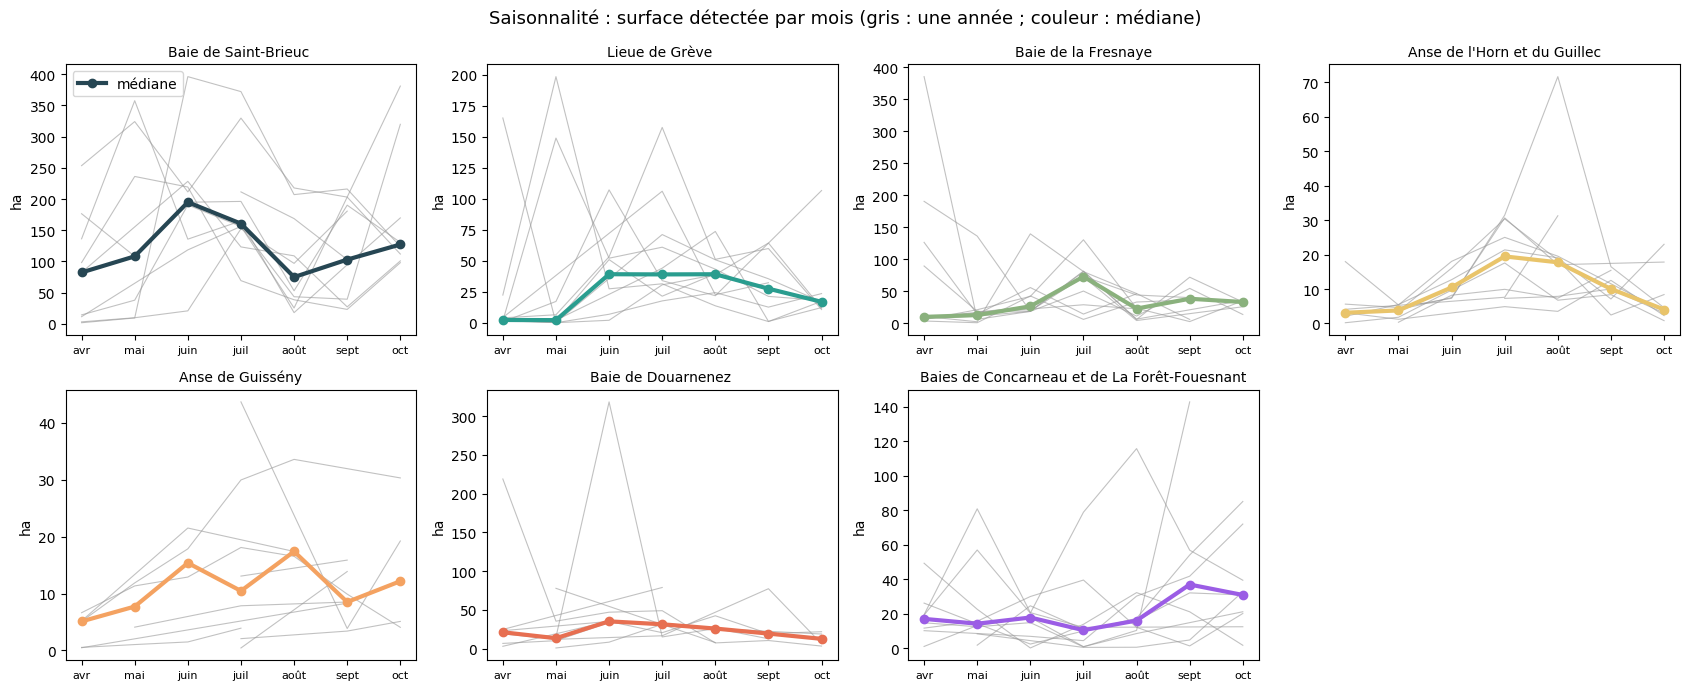

In [5]:
m = pd.read_csv(P / "s2_mensuel_corrige.csv")
col = "ulva_corr_s020"
noms_mois = ["avr", "mai", "juin", "juil", "août", "sept", "oct"]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, k in zip(axes.flat, baies):
    g = m[m["baie"] == k]
    for a, ga in g.groupby("annee"):
        ax.plot(ga["mois"].values, ga[col].values, color="#999999", lw=0.8, alpha=0.6)
    med = g.groupby("mois")[col].median()
    ax.plot(med.index.values, med.values, color=COULEURS[k], lw=3, marker="o", label="médiane")
    ax.set_xticks(range(4, 11)); ax.set_xticklabels(noms_mois, fontsize=8)
    ax.set_title(baies[k]["nom"].split("(")[0], fontsize=10); ax.set_ylabel("ha")
axes.flat[-1].axis("off")
axes.flat[0].legend()
fig.suptitle("Saisonnalité : surface détectée par mois (gris : une année ; couleur : médiane)", fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])

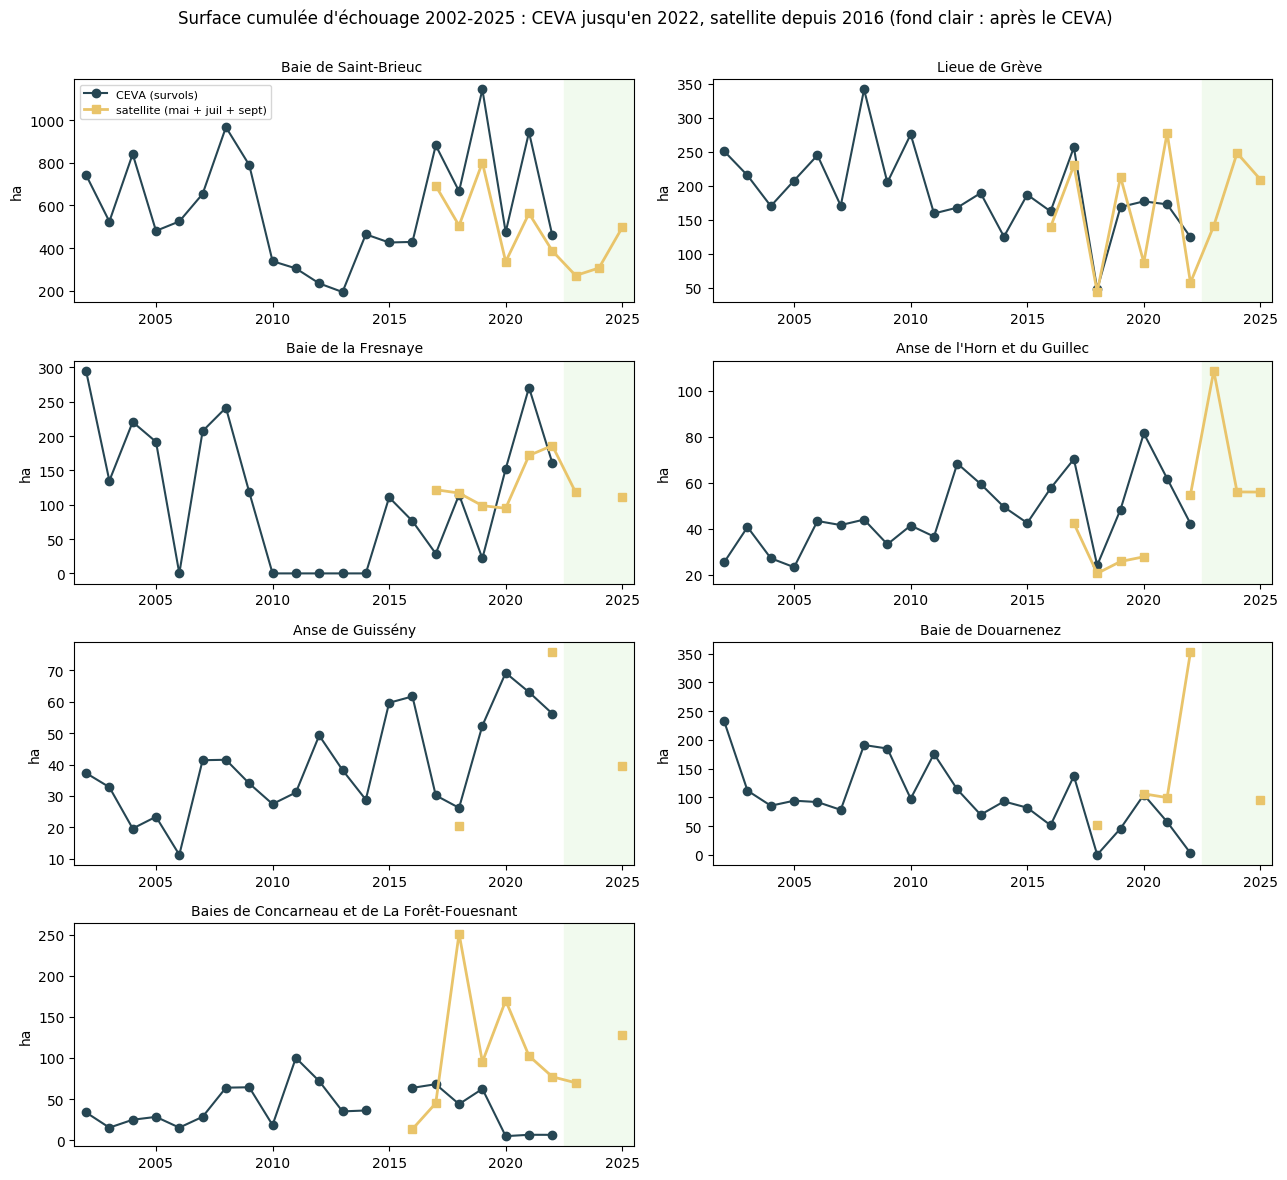

In [6]:
a = pd.read_csv(P / "s2_annuel_corrige.csv")
ce = pd.read_csv(P / "baies_annuel.csv")
fig, axes = plt.subplots(4, 2, figsize=(13, 12))
for ax, k in zip(axes.flat, baies):
    c = ce[ce["baie"] == k]
    s = a[a["baie"] == k]
    ax.plot(c["annee"].values, c["surface_ha"].values, color="#264653", marker="o", label="CEVA (survols)")
    ax.plot(s["annee"].values, s["ulva_ha_s020"].values, color="#e9c46a", marker="s", lw=2,
            label="satellite (mai + juil + sept)")
    ax.axvspan(2022.5, 2025.5, color="#f1faee")
    ax.set_title(baies[k]["nom"].split("(")[0], fontsize=10); ax.set_xlim(2001.5, 2025.5)
    ax.set_ylabel("ha")
axes.flat[-1].axis("off")
axes.flat[0].legend(fontsize=8)
fig.suptitle("Surface cumulée d'échouage 2002-2025 : CEVA jusqu'en 2022, satellite depuis 2016 (fond clair : après le CEVA)",
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.95])

## 5. À quel point le satellite est-il proche du CEVA ?

In [7]:
d = a.dropna(subset=["ulva_ha_s020", "surface_ha"]).copy()
d["sat"] = d["ulva_ha_s020"]
d["ecart"] = d["sat"] - d["surface_ha"]
ecarts = d.groupby("baie").apply(lambda g: pd.Series({
    "années": len(g),
    "CEVA moyen (ha)": g["surface_ha"].mean(),
    "satellite moyen (ha)": g["sat"].mean(),
    "écart moyen (ha)": g["ecart"].abs().mean(),
    "écart (%)": 100 * g["ecart"].abs().sum() / g["surface_ha"].sum(),
    "biais (%)": 100 * (g["sat"].sum() / g["surface_ha"].sum() - 1),
    "suit les années (Spearman)": g["sat"].corr(g["surface_ha"], method="spearman"),
}))
ecarts.round(1)

,années,CEVA moyen (ha),satellite moyen (ha),écart moyen (ha),écart (%),biais (%),suit les années (Spearman)
baie,,,,,,,
concarneau_la_foret,7.0,36.5,107.8,92.2,252.3,195.0,-0.6
douarnenez,4.0,41.1,152.6,111.4,271.0,271.0,0.4
fresnaye,6.0,124.9,131.7,59.0,47.3,5.5,0.5
guisseny,2.0,41.2,48.2,12.6,30.7,16.9,1.0
horn_guillec,5.0,53.2,34.2,24.1,45.2,-35.8,0.3
lieue_de_greve,7.0,158.6,149.8,51.4,32.4,-5.6,0.7
saint_brieuc,6.0,761.8,547.4,214.5,28.2,-28.2,0.9


## Ce qu'on retient

**Proximité au CEVA (cumul mai + juillet + septembre, 2016-2022, seuil NDVI 0,2)**

| Baie | Écart moyen | Biais | Suit les bonnes et mauvaises années |
|---|---|---|---|
| Saint-Brieuc | 28 % | −28 % (sous-estime) | oui (0,89) |
| Lieue de Grève | 32 % | −6 % | oui (0,71) |
| Fresnaye | 47 % | +6 % | moyennement (0,54) |
| Horn-Guillec | 45 % | −36 % | peu (0,30) |
| Guissény | 31 % | +17 % | 2 années seulement |
| Douarnenez | 271 % | +271 % | peu (0,40), 4 années |
| Concarneau-La Forêt | 252 % | +195 % | non (−0,61) |

- **Sur 5 baies sur 7, le satellite est à 30-45 % du CEVA**, presque sans biais pour la Lieue de Grève, la Fresnaye et Guissény. Sans Concarneau, l'écart global est de 37 %.
- **Saint-Brieuc est sous-estimé d'environ 28 %, mais de façon régulière** : un simple facteur d'échelle suffit, et le satellite suit très bien les années (0,89).
- **Concarneau et Douarnenez restent faux.** Les polygones CEVA y englobent rochers et petits fonds, alors que le CEVA ne compte que les échouages sur sable. Il faudra limiter la zone aux plages (polygones OpenStreetMap `natural=beach`). Le CEVA lui-même y est suspect (Douarnenez : 0 ha en 2018 et 3 ha en 2022).
- **La marée est le principal piège.** Les récifs couverts d'algues fixées ne se découvrent qu'aux plus basses mers, plus souvent captées depuis 2022 (plus de satellites). Ils sont maintenant exclus : un pixel détecté dans au moins 70 % des scènes où il est découvert est considéré comme fixe. Le saut artificiel de 2022 a disparu.
- **Les cartes de fréquence montrent où s'accumulent les ulves** : fond de baie à Saint-Brieuc (anses d'Yffiniac et de Morieux), bande centrale en Lieue de Grève.
